# Group 20 – Part C: Time Split, Evaluation and Baseline Models
**Task:** predict taxi trip duration (minutes) at pickup – regression.
**Input:** A's cleaned trips and B's features. **Output:** the shared evaluation function, baseline and linear-model results, and the parallel-training evidence.

| Setting | How to set |
|---|---|
| `ETA_DATA` | A's sample Parquet (development) **or** an A run folder with `cleaned_parts/` (full month) |
| `ETA_WORKERS` | worker counts to benchmark, e.g. `1 2 4` |
| `ETA_VAL_START`, `ETA_TEST_START` | split dates, shared with B and D |
| `ETA_RUN` | output folder name under `outputs/` |

On Rockhill: `bash run_rockhill_c.sh` (uses the `cs4207` partition).

In [1]:
import os
for v in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'NUMEXPR_NUM_THREADS'):
    os.environ[v] = '1'          # one BLAS thread per process: fair timings, repeatable sums
import sys, time
from pathlib import Path
import numpy as np, pandas as pd

T_START = time.perf_counter()
A_DIR = Path(os.environ.get('ETA_A_DIR', '../Group20_ETA_A'))
B_DIR = Path(os.environ.get('ETA_B_DIR', '../Group20_ETA_B'))
DATA = os.environ.get('ETA_DATA', str(A_DIR / 'outputs/local_jan2026/sample_100k.parquet'))
WORKERS = [int(w) for w in os.environ.get('ETA_WORKERS', '1 2 4').split()]
VAL_START = os.environ.get('ETA_VAL_START', '2026-01-22')
TEST_START = os.environ.get('ETA_TEST_START', '2026-01-27')
RUN = os.environ.get('ETA_RUN', 'local_sample')

sys.path[:0] = ['.', str(A_DIR), str(B_DIR)]
from handoff import chronological_split, inputs_and_target          # A's contract
from b_features import FeatureBuilder, load_cleaned                 # B's features
print('data:', DATA, '| run:', RUN, '| workers:', WORKERS)

data: ../Group20_ETA_Final/outputs/local_full/clean | run: local_full | workers: [1, 2, 4]


In [2]:
df = load_cleaned(DATA)
train, val, test = chronological_split(df, VAL_START, TEST_START)
Xtr, ytr = inputs_and_target(train); Xva, yva = inputs_and_target(val); Xte, yte = inputs_and_target(test)
fb = FeatureBuilder()                                                # fitted on TRAIN only
F_tr = fb.fit_transform(Xtr, ytr); F_va = fb.transform(Xva); F_te = fb.transform(Xte)
print(f'{len(df):,} trips, {F_tr.shape[1]} features from B')

3,504,372 trips, 31 features from B


In [3]:
import json, platform, shutil, subprocess
import matplotlib; matplotlib.use('Agg'); import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
import sklearn
from threadpoolctl import threadpool_info

import c_parallel as cp, c_figures as figs
from c_models import (Scoreboard, boundary_trips, check_split, evaluate, make_baselines,
                      time_workers, to_minutes, with_calendar)

C_START = time.perf_counter()
C_OUT = Path('outputs') / RUN; C_FIG = C_OUT / 'figures'; C_FIG.mkdir(parents=True, exist_ok=True)
CACHE = Path(os.environ.get('ETA_CACHE', str(C_OUT / 'cache')))   # memory-mapped arrays (~1.5 GB for a month), deleted at the end
SEED, REPEATS = cp.SEED, 3               # every random draw in Part C starts from SEED
GD_ITERS, GD_BENCH_ITERS = 400, 100      # full training / benchmark length of gradient descent
PAR = max(WORKERS)
STORM_DAY = '2026-01-25'                 # see section C1

def c_show(fig, name):
    fig.savefig(C_FIG / f'{name}.png', dpi=200, bbox_inches='tight'); plt.close(fig)
    display(Image(str(C_FIG / f'{name}.png'), width=850))

def hardware():
    cpu = platform.processor()
    if Path('/proc/cpuinfo').exists():
        cpu = next((l.split(':')[1].strip() for l in open('/proc/cpuinfo') if 'model name' in l), cpu)
    cores = len(os.sched_getaffinity(0)) if hasattr(os, 'sched_getaffinity') else None
    if cores is None:
        try:
            import psutil; cores = len(psutil.Process().cpu_affinity())
        except Exception:
            cores = os.cpu_count()
    gpu = 'none visible'
    if shutil.which('nvidia-smi'):
        r = subprocess.run(['nvidia-smi', '--query-gpu=name', '--format=csv,noheader'], capture_output=True, text=True)
        gpu = (r.stdout.strip().replace('\n', ', ') if r.returncode == 0 else '') or gpu
    return {'host': platform.node() if platform.system() != 'Windows' else 'local Windows laptop', 'cpu': cpu,
            'cores_total': os.cpu_count(), 'cores_usable': cores, 'slurm_cpus': os.environ.get('SLURM_CPUS_PER_TASK'),
            'gpu': gpu + ' (not used in Part C)', 'python': platform.python_version(), 'platform': platform.platform(),
            'numpy': np.__version__, 'pandas': pd.__version__, 'scikit-learn': sklearn.__version__,
            'blas_threads': sorted({p['num_threads'] for p in threadpool_info()})}

c_sum = {'run': RUN, 'data_source': Path(DATA).name, 'environment': hardware(),
         'config': {'seed': SEED, 'repeats': REPEATS, 'workers': WORKERS, 'shards': cp.N_SHARDS,
                    'gd_iterations': GD_ITERS, 'gd_benchmark_iterations': GD_BENCH_ITERS, 'alphas': list(cp.ALPHAS),
                    'val_start': VAL_START, 'test_start': TEST_START}}
pd.Series(c_sum['environment']).to_frame('value')

,value
host,local Windows laptop
cpu,"Intel64 Family 6 Model 183 Stepping 1, Genuine..."
cores_total,32
cores_usable,8
slurm_cpus,None
gpu,NVIDIA GeForce RTX 4060 Laptop GPU (not used i...
python,3.12.10
platform,Windows-11-10.0.26300-SP0
numpy,2.5.5
pandas,3.1.1


In [4]:
# Contract check: the features built here must match the ones B published
rows = []
for name, F, y in (('train', F_tr, ytr), ('validation', F_va, yva), ('test', F_te, yte)):
    ex = pd.read_parquet(B_DIR / f'outputs/local_sample/features_{name}.parquet')
    if len(ex) != len(F):
        print('B published the 100k sample; this run uses other data, so the check is skipped'); break
    cols = list(F.columns)
    diff = np.abs(ex[cols].to_numpy('float64') - F[cols].to_numpy('float64'))
    rows.append({'split': name, 'rows': len(ex), 'targets_identical': bool(np.array_equal(ex['duration_minutes'], y)),
                 'cells_that_differ': int((diff > 0).sum()), 'largest_difference': float(diff.max())})
if rows:
    c_sum['cross_machine'] = rows
    display(pd.DataFrame(rows))

B published the 100k sample; this run uses other data, so the check is skipped


## C1. Time-based split
Trips are split by pickup time, never at random. A random split would let the model learn from trips that happen *after* the ones it is tested on.

| Part | Dates | Why |
|---|---|---|
| Train | 1–21 Jan | exactly three weeks, so every weekday appears three times |
| Validation | 22–26 Jan | used for every choice: features, target scale, history length, ridge strength |
| Test | 27–31 Jan | scored once, at the end |

In [5]:
split_table = check_split(train, val, test, total_rows=len(df))      # raises if the split is not chronological
c_sum['split'] = split_table.astype({'first_pickup': str, 'last_pickup': str}).reset_index().to_dict('records')
c_sum['boundary_trips'] = {'train_to_validation': boundary_trips(train, VAL_START),
                           'validation_to_test': boundary_trips(val, TEST_START)}
print('trips that start before a boundary and end after it:', c_sum['boundary_trips'])
split_table

trips that start before a boundary and end after it: {'train_to_validation': 610, 'validation_to_test': 739}


,rows,share_%,days,first_pickup,last_pickup,mean_min,median_min
split,,,,,,,
train,2348057,67.0,21,2026-01-01,2026-01-21 23:59:59,16.57,13.07
validation,507763,14.5,5,2026-01-22,2026-01-26 23:59:55,16.16,12.98
test,648552,18.5,5,2026-01-27,2026-01-31 23:59:59,20.10,16.05


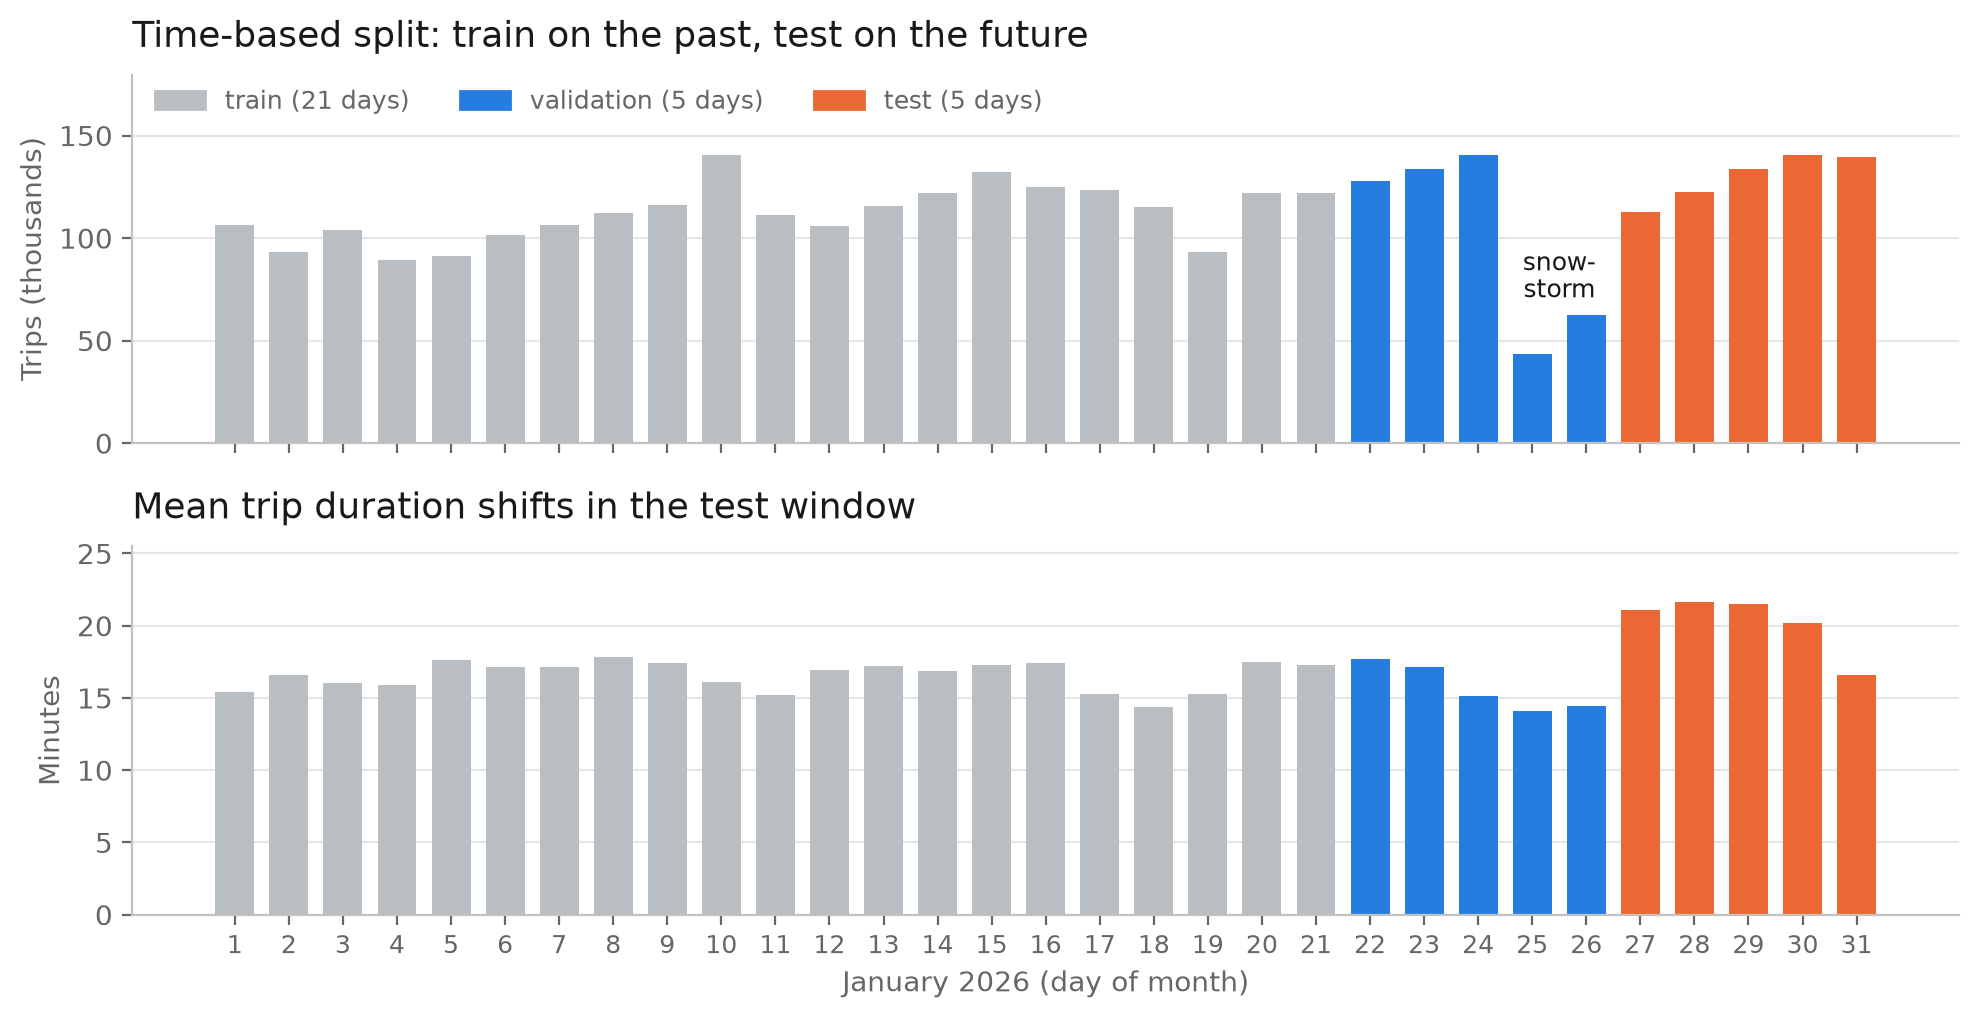

{'train_daily_mean_min': 14.3,
 'train_daily_mean_max': 17.8,
 'jan27_30_mean': 21.1,
 'storm_day_trips': 43345,
 'day_before_trips': 140373}

In [6]:
day = df['pickup_datetime'].dt.normalize()
daily = df.groupby(day)['duration_minutes'].agg(trips='size', mean_min='mean')
daily['split'] = np.where(daily.index < pd.Timestamp(VAL_START), 'train',
                          np.where(daily.index < pd.Timestamp(TEST_START), 'validation', 'test'))
c_show(figs.split_timeline(daily, STORM_DAY), 'C_split_timeline')
normal = daily.loc[daily['split'] == 'train', 'mean_min']
storm_after = daily.loc['2026-01-27':'2026-01-30', 'mean_min']
c_sum['shift'] = {'train_daily_mean_min': round(float(normal.min()), 1), 'train_daily_mean_max': round(float(normal.max()), 1),
                  'jan27_30_mean': round(float(storm_after.mean()), 1),
                  'storm_day_trips': int(daily.loc[STORM_DAY, 'trips']), 'day_before_trips': int(daily.loc['2026-01-24', 'trips'])}
c_sum['shift']

**What the split reveals.** New York had a major snowstorm on 25 January 2026 ([ABC7 New York, NWS totals](https://abc7ny.com/post/how-snow-winter-storm-12526-snowfall-totals-nyc-ny-nj-ct/18470009/)). Trip counts collapse that day, and on 27–30 January trips take several minutes longer than on any training day. The test window is therefore harder than validation. We keep the agreed dates: moving the boundary after seeing this would mean choosing the test set to look good. Section C9 shows the effect day by day.

The few trips that cross a boundary are kept; they are too few to matter, and we report the count.

## C2. Shared evaluation function
`evaluate(y_true, y_pred)` is used for every model in Parts C and D. It always works in **minutes**; a model trained on `log1p(duration)` is converted back with `to_minutes()` first, and the function warns if predictions still look like logs.

| Metric | Meaning |
|---|---|
| **MAE** | average error in minutes – our main metric, because it reads as "how many minutes off is the ETA" |
| **RMSE** | punishes large misses more |
| **R²** | share of variance explained; 0 = no better than predicting the mean |
| **bias** | mean of (prediction − truth); negative = we promise too short a trip |

In [7]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
y_demo, p_demo = yva.to_numpy()[:5000], np.full(min(5000, len(yva)), 15.0)
ours, ref = evaluate(y_demo, p_demo), (mean_absolute_error(y_demo, p_demo), mean_squared_error(y_demo, p_demo) ** 0.5, r2_score(y_demo, p_demo))
assert np.allclose([ours['MAE'], ours['RMSE'], ours['R2']], ref)
print('evaluate() matches scikit-learn:', {k: round(v, 4) for k, v in ours.items()})
board = Scoreboard()

evaluate() matches scikit-learn: {'n': 5000, 'MAE': 8.5973, 'RMSE': 13.3328, 'R2': -0.0028, 'bias': -0.7012}


## C3. Baselines
Every later model has to beat these. Each one is fitted on the training split only.

- **Constant** – the training median (best constant for MAE) or mean (R² ≈ 0 by construction).
- **Same weekday & hour** – the lecture's "same hour last week" idea: median duration for that weekday and hour.
- **Zone-pair median** – median duration for the same pickup and dropoff zone; an unseen pair backs off to the pickup zone, then to the overall median.

In [8]:
Ctr, Cva, Cte = with_calendar(Xtr), with_calendar(Xva), with_calendar(Xte)
base_pred = {}
for name, m in make_baselines().items():
    m.fit(Ctr, ytr)
    base_pred[name] = (m.predict(Cva), m.predict(Cte))
    board.add(name, 'validation', yva, base_pred[name][0], group='baseline')
    board.add(name, 'test', yte, base_pred[name][1], group='baseline')
board.table().round(3)

,validation_MAE,validation_RMSE,validation_R2,validation_bias,test_MAE,test_RMSE,test_R2,test_bias
model,,,,,,,,
Constant (train median),8.190,13.054,-0.059,-3.090,10.694,17.195,-0.201,-7.029
Constant (train mean),8.733,12.690,-0.001,0.418,10.367,16.083,-0.050,-3.522
Same weekday & hour,8.156,12.988,-0.049,-3.060,10.578,17.004,-0.174,-6.823
Zone-pair median,4.209,7.170,0.680,-1.394,7.051,11.460,0.467,-5.329


**Reading the table.** Knowing only *when* a trip starts barely helps. Knowing *where* it goes cuts the error sharply, which agrees with B's EDA. The zone-pair median is the baseline to beat.

## C4. Features for the linear models
Linear models get B's features with three columns removed, and each removal has a reason. Scaling statistics come from the training rows only.

In [9]:
sets = cp.feature_sets(F_tr.columns)
display(pd.Series(cp.NOT_FOR_LINEAR, name='why it is dropped').to_frame())
pd.DataFrame({k: {'columns': len(i), 'products': len(p), 'total inputs': len(i) + len(p)} for k, (i, p) in sets.items()}).T.assign(
    content=['calendar, zone flags, passengers (no learned encodings)', 'calendar + B\'s target encodings',
             'encoded + products of encodings with time bands / flags'])

,why it is dropped
day_of_month,"train covers days 1-21, so days 22-31 are pure..."
band_night,dummy trap: the five band columns always sum to 1
is_peak,exactly band_morning_peak + band_afternoon_peak


,columns,products,total inputs,content
calendar,17,0,17,"calendar, zone flags, passengers (no learned e..."
encoded,28,0,28,calendar + B's target encodings
interactions,28,87,115,encoded + products of encodings with time band...


## C5. Task parallelism: hyperparameter search
One trial = one (feature set, target scale, history length) combination; inside a trial all ridge strengths α share one Gram matrix (α = 0 is plain linear regression). 3 × 2 × 3 = **18 trials, 126 configurations**.

**Why the trials are independent:** each one reads the same read-only arrays, fits its own weights on training rows and is scored on validation. No trial needs another trial's result. The test split is not loaded by the search at all.

**How it runs:** each trial is a separate job in a process pool; workers memory-map the arrays instead of receiving copies. Jobs start longest-first. Results are sorted by trial id, so the answer does not depend on which job finishes first.

In [10]:
start_row = {d: int((train['pickup_datetime'] < pd.Timestamp(VAL_START) - pd.Timedelta(days=d)).sum()) for d in (7, 14, 21)}
trials = cp.make_trials(sets)
tasks = [(t, sets[t['features']], start_row[t['history_days']]) for t in trials]
search_paths = cp.save_arrays(CACHE / 'search', Xtr=F_tr.to_numpy('float64'), ytr=ytr.to_numpy('float64'),
                              Xva=F_va.to_numpy('float64'), yva=yva.to_numpy('float64'))
search_time, search_last, search_hash = time_workers(lambda w: cp.run_search(search_paths, tasks, w),
                                                     lambda o: cp.rows_fingerprint(o['rows']), WORKERS, REPEATS)
search = search_last[1]
c_sum['search_benchmark'] = search_time.round(4).to_dict('records'); c_sum['search_hash'] = search_hash
print('all outputs identical for every worker count and repeat, fingerprint', search_hash)
search_time.round(3)

all outputs identical for every worker count and repeat, fingerprint 6727f0e94437


,workers,mean_s,std_s,compute_s,startup_s,speedup,efficiency,speedup_no_startup,outputs_equal
0,1,12.723,0.086,12.723,0.000,1.000,1.000,1.000,True
1,2,7.058,0.068,6.891,0.167,1.803,0.901,1.846,True
2,4,4.335,0.025,4.143,0.192,2.935,0.734,3.071,True


In [11]:
res = pd.DataFrame(search['rows'])
best = cp.best_row(search['rows'])
c_sum['best'] = best; c_sum['n_configs'] = len(res); c_sum['n_trials'] = len(trials)
print('best on validation:', {k: (round(v, 4) if isinstance(v, float) else v) for k, v in best.items()})
res.groupby(['features', 'target', 'history_days'])['MAE'].min().unstack().round(3)[[7, 14, 21]].rename_axis(columns='history (days) → best validation MAE')

best on validation: {'trial': 14, 'features': 'interactions', 'target': 'log', 'history_days': 21, 'alpha': 0.0, 'MAE': 4.0223, 'RMSE': 6.9782, 'R2': 0.6973}


history (days) → best validation MAE     7      14     21
features     target                                      
calendar     log                      7.221  7.203  7.195
             raw                      7.636  7.671  7.640
encoded      log                      4.255  4.171  4.152
             raw                      5.098  5.113  5.066
interactions log                      4.156  4.042  4.022
             raw                      4.543  4.447  4.408

In [12]:
alpha_view = res[(res.target == best['target']) & (res.history_days == best['history_days'])].pivot(
    index='alpha', columns='features', values='MAE')[['calendar', 'encoded', 'interactions']]
c_sum['alpha_spread_best_set'] = {'best': float(alpha_view[best['features']].min()), 'alpha0': float(alpha_view[best['features']].iloc[0]),
                                  'alpha_max': float(alpha_view[best['features']].iloc[-1])}
alpha_view.round(3)

features,calendar,encoded,interactions
alpha,,,
0.0,7.195,4.156,4.022
1.0,7.195,4.156,4.022
10.0,7.195,4.156,4.024
100.0,7.195,4.156,4.032
1000.0,7.195,4.155,4.056
10000.0,7.196,4.152,4.086
100000.0,7.205,4.176,4.142


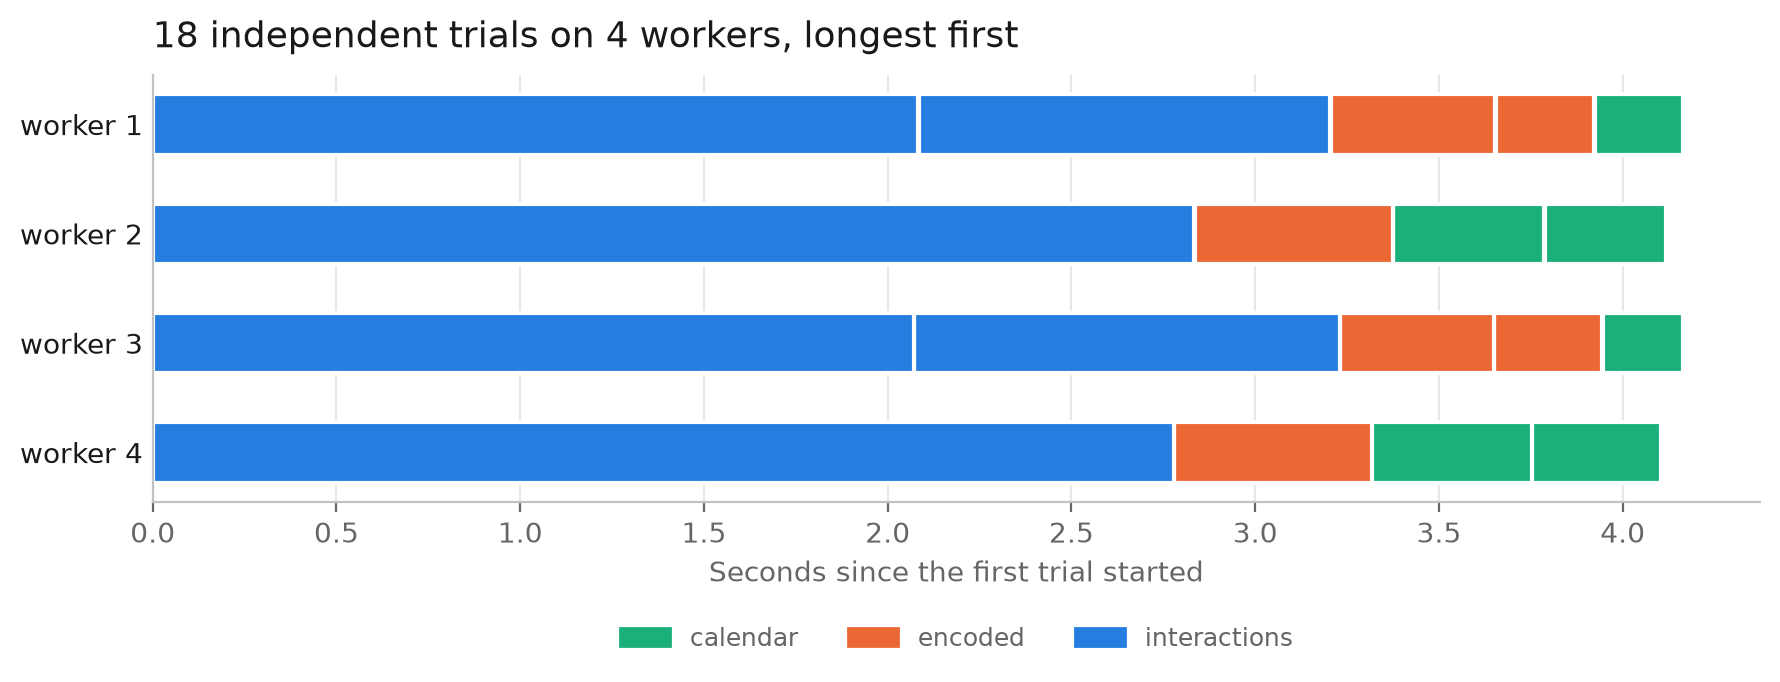

{'shortest_trial_s': 0.169,
 'longest_trial_s': 2.266,
 'ratio': 13.4,
 'sum_trials_s': 12.79,
 'bound_by_longest_trial': 5.65,
 'slowdown_of_a_trial_in_parallel': 1.29,
 'compute_longest_first_s': 4.127,
 'compute_listed_order_s': 4.961}

In [13]:
run_par = search_last[PAR]
c_show(figs.trial_gantt(run_par['results'], PAR), 'C_trial_gantt')
secs = pd.Series({r['trial']: r['seconds'] for r in run_par['results']})
seq = pd.Series({r['trial']: r['seconds'] for r in search['results']})
naive = [cp.run_search(search_paths, tasks, PAR, longest_first=False)['compute'] for _ in range(REPEATS)]
longest = [cp.run_search(search_paths, tasks, PAR)['compute'] for _ in range(REPEATS)]
c_sum['imbalance'] = {'shortest_trial_s': round(float(seq.min()), 3), 'longest_trial_s': round(float(seq.max()), 3),
                      'ratio': round(float(seq.max() / seq.min()), 1), 'sum_trials_s': round(float(seq.sum()), 2),
                      'bound_by_longest_trial': round(float(seq.sum() / seq.max()), 2),
                      'slowdown_of_a_trial_in_parallel': round(float(secs.sum() / seq.sum()), 2),
                      'compute_longest_first_s': round(float(np.mean(longest)), 3), 'compute_listed_order_s': round(float(np.mean(naive)), 3)}
c_sum['imbalance']

**Load imbalance.** Trial cost grows with rows × inputs², so the interaction trials dominate. With jobs started in listed order the long ones come last and workers sit idle at the end; starting the longest first lets the short trials fill the gaps. However many workers are added, the speedup can never exceed *total work ÷ longest trial* (`bound_by_longest_trial`). Each trial also runs somewhat slower when several share the memory bus (`slowdown_of_a_trial_in_parallel`).

## C6. Linear and ridge results
Weights come from the search (train only). Predictions are converted to minutes and scored with the shared function. We check our block-wise solver against scikit-learn on the same data.

In [14]:
def pick(features, alpha_zero=False):
    rows = [r for r in search['rows'] if r['features'] == features and (not alpha_zero or r['alpha'] == 0)]
    return cp.best_row(rows)

def predict(row, F):
    idx, pairs = sets[row['features']]
    m = search['results'][row['trial']]['model']
    one = {**m, 'W': m['W'][:, [m['alphas'].index(row['alpha'])]]}
    return cp.predict_path(F.to_numpy('float64'), one, idx, pairs, row['target'])[:, 0]

chosen = {'Linear: calendar features only': pick('calendar', alpha_zero=True),
          'Linear: + zone encodings': pick('encoded', alpha_zero=True),
          'Ridge: + zone encodings': pick('encoded'),
          'Tuned linear: + interactions': pick('interactions')}
lin_pred = {}
for name, row in chosen.items():
    lin_pred[name] = (predict(row, F_va), predict(row, F_te))
    got = board.add(name, 'validation', yva, lin_pred[name][0])
    assert np.isclose(got['MAE'], row['MAE'], atol=1e-9)             # same number as inside the search
    board.add(name, 'test', yte, lin_pred[name][1])
c_sum['chosen'] = chosen
pd.DataFrame(chosen).T[['features', 'target', 'history_days', 'alpha', 'MAE']].rename(columns={'MAE': 'validation MAE'})

,features,target,history_days,alpha,validation MAE
Linear: calendar features only,calendar,log,21,0.0,7.19536
Linear: + zone encodings,encoded,log,21,0.0,4.155582
Ridge: + zone encodings,encoded,log,21,10000.0,4.152455
Tuned linear: + interactions,interactions,log,21,0.0,4.022292


In [15]:
from sklearn.linear_model import LinearRegression, Ridge
row = chosen['Ridge: + zone encodings']
idx, _ = sets['encoded']; m = search['results'][row['trial']]['model']; s0 = start_row[row['history_days']]
Z = (F_tr.to_numpy('float64')[s0:][:, idx] - m['mean']) / m['scale']
y_fit = np.log1p(ytr.to_numpy()[s0:]) if row['target'] == 'log' else ytr.to_numpy()[s0:]
gap_ridge = float(np.abs(Ridge(alpha=row['alpha'] or 1.0).fit(Z, y_fit).coef_ - cp.fit_ridge_path(F_tr.to_numpy('float64')[s0:], y_fit, idx, [], (row['alpha'] or 1.0,))['W'][:, 0]).max())
gap_ols = float(np.abs(LinearRegression().fit(Z, y_fit).coef_ - m['W'][:, m['alphas'].index(0.0)]).max())
c_sum['sklearn_gap'] = {'ridge': gap_ridge, 'ols': gap_ols}
assert gap_ridge < 1e-6 and gap_ols < 1e-6
print(f'largest weight difference to scikit-learn: ridge {gap_ridge:.1e}, linear {gap_ols:.1e}')

largest weight difference to scikit-learn: ridge 1.3e-13, linear 1.5e-13


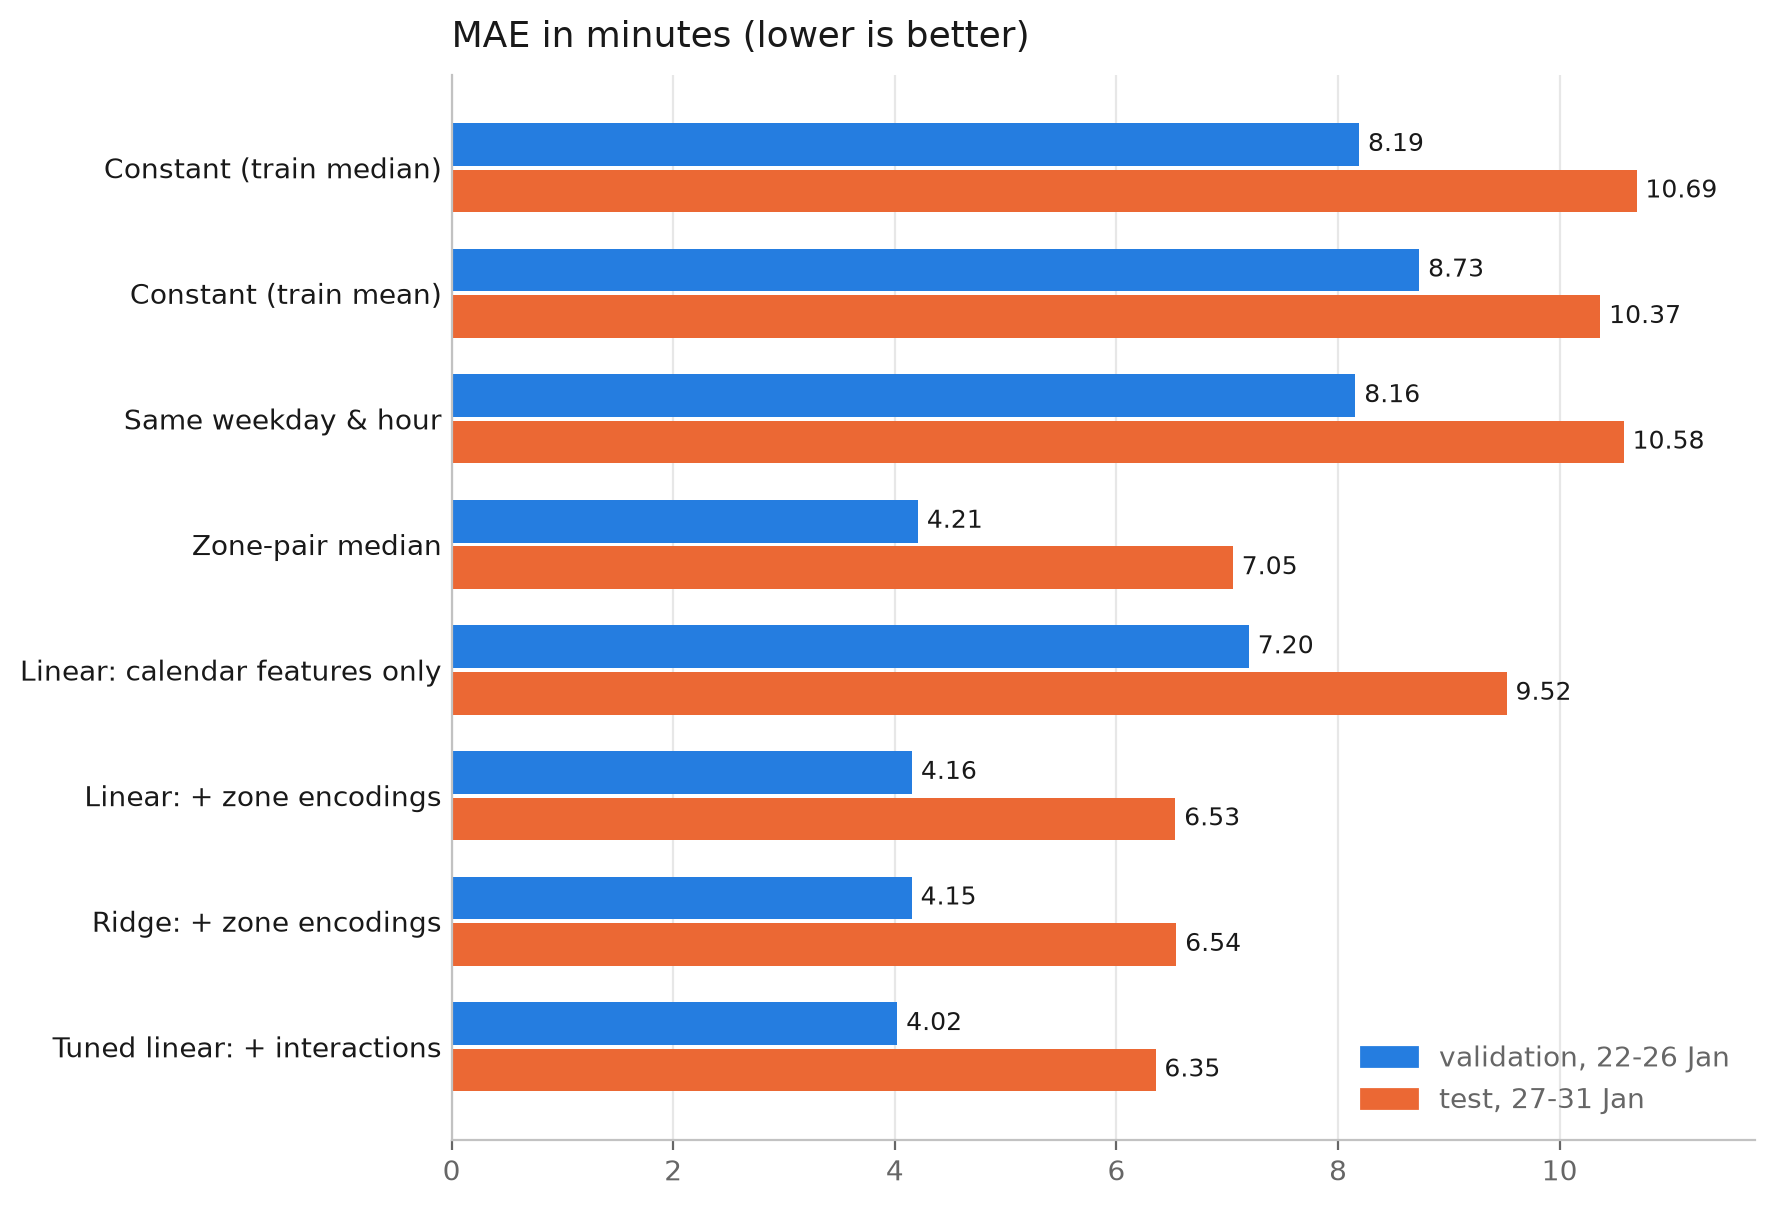

,validation_MAE,validation_RMSE,validation_R2,validation_bias,test_MAE,test_RMSE,test_R2,test_bias
model,,,,,,,,
Constant (train median),8.190,13.054,-0.059,-3.090,10.694,17.195,-0.201,-7.029
Constant (train mean),8.733,12.690,-0.001,0.418,10.367,16.083,-0.050,-3.522
Same weekday & hour,8.156,12.988,-0.049,-3.060,10.578,17.004,-0.174,-6.823
Zone-pair median,4.209,7.170,0.680,-1.394,7.051,11.460,0.467,-5.329
Linear: calendar features only,7.195,11.729,0.145,-2.287,9.522,15.489,0.026,-5.850
Linear: + zone encodings,4.156,7.401,0.660,-1.010,6.531,11.165,0.494,-4.675
Ridge: + zone encodings,4.152,7.432,0.657,-1.045,6.540,11.202,0.490,-4.707
Tuned linear: + interactions,4.022,6.978,0.697,-0.914,6.353,10.593,0.544,-4.559


In [16]:
table = board.table()
best_name = min(chosen, key=lambda k: table.loc[k, 'validation_MAE'])        # chosen on validation
c_show(figs.model_comparison(table), 'C_model_comparison')
board.save(C_OUT / 'C_scoreboard.csv')
table.round(3)

In [17]:
zp, lin, rid = 'Zone-pair median', 'Linear: + zone encodings', 'Ridge: + zone encodings'
val_of = lambda n, metric='MAE': table.loc[n, f'validation_{metric}']
change = lambda n, metric='MAE': 100 * (val_of(n, metric) / val_of(zp, metric) - 1)
display(Markdown(f'''
**Reading the results**
- Plain linear regression on the zone encodings changes validation MAE by {change(lin):+.1f}% and RMSE by {change(lin, "RMSE"):+.1f}% against the zone-pair median: the encodings already carry most of what the lookup knows.
- Products of encodings with time bands and zone flags help most: validation MAE {val_of(best_name):.2f} min, {change(best_name):+.1f}% against the zone-pair median. The effect of the time of day depends on the route.
- Ridge strength hardly matters (MAE {val_of(lin):.3f} → {val_of(rid):.3f} with α = {chosen[rid]["alpha"]:g}; the best model overall uses α = {chosen[best_name]["alpha"]:g}). With {len(train):,} training rows there is little to regularise.
- Every model is worse on test and biased low (best model {table.loc[best_name, "test_bias"]:+.1f} min): all of them predict normal traffic for the days after the storm.
'''))


**Reading the results**
- Plain linear regression on the zone encodings changes validation MAE by -1.3% and RMSE by +3.2% against the zone-pair median: the encodings already carry most of what the lookup knows.
- Products of encodings with time bands and zone flags help most: validation MAE 4.02 min, -4.4% against the zone-pair median. The effect of the time of day depends on the route.
- Ridge strength hardly matters (MAE 4.156 → 4.152 with α = 10000; the best model overall uses α = 0). With 2,348,057 training rows there is little to regularise.
- Every model is worse on test and biased low (best model -4.6 min): all of them predict normal traffic for the days after the storm.


## C7. Gradient computation (all-reduce)
Ridge has a closed form, so we can check the parallel gradient against a known answer. Full-batch accelerated gradient descent minimises $\\frac{1}{2n}\\lVert Zw-t\\rVert^2 + \\frac{\\alpha}{2n}\\lVert w\\rVert^2$.

1. **Shard:** training rows are cut into 8 contiguous shards of equal size. Every row costs the same, so equal rows = equal work. The number of shards is fixed and does not depend on the number of workers.
2. **Map:** each worker computes the gradient **sum** and the row **count** of its shard with the same function.
3. **Reduce:** the parent adds sums and counts **in shard order**, divides once, and updates one shared weight vector.

Shards are independent because, for fixed weights, each row's gradient depends on that row only.

In [18]:
alpha_gd = float(row['alpha'])
Zva = (F_va.to_numpy('float64')[:, idx] - m['mean']) / m['scale']
common = dict(Zva=Zva, yva=yva.to_numpy('float64'), t_mean=np.array([m['t_mean']]))
gd_paths = {'full': cp.save_arrays(CACHE / 'gd_full', Z=Z, t=y_fit - m['t_mean'], **common)}
gd_args = dict(alpha=alpha_gd, lam_max=m['eig_max'], lam_min=m['eig_min'])
w_exact = m['W'][:, m['alphas'].index(row['alpha'])]

trace = []
gd = cp.train_gd(gd_paths['full'], iters=GD_ITERS, workers=PAR, trace=trace, **gd_args)
minutes = lambda w: to_minutes(Zva @ w + m['t_mean'])
conv = pd.DataFrame([{'iteration': k, 'largest weight error': np.abs(trace[k - 1] - w_exact).max(),
                      'largest prediction gap (min)': np.abs(minutes(trace[k - 1]) - minutes(w_exact)).max(),
                      'validation MAE': evaluate(yva, minutes(trace[k - 1]))['MAE']} for k in (10, 50, 100, 200, 300, GD_ITERS)])
c_sum['gd_convergence'] = {'iterations': GD_ITERS, 'max_weight_error': float(conv.iloc[-1, 1]), 'max_prediction_gap_min': float(conv.iloc[-1, 2]),
                           'validation_MAE': float(conv.iloc[-1, 3]), 'closed_form_MAE': evaluate(yva, minutes(w_exact))['MAE'], 'rows': len(Z), 'features': Z.shape[1]}
assert row['target'] == 'log' and conv.iloc[-1, 2] < 0.01
conv

,iteration,largest weight error,largest prediction gap (min),validation MAE
0,10,1.562349e-01,2.013876e+01,4.206233
1,50,1.625462e-02,1.318316e+00,4.155199
2,100,2.956635e-03,3.118705e-01,4.152635
3,200,1.635029e-05,1.165683e-03,4.152454
4,300,4.995731e-07,4.869576e-05,4.152455
5,400,7.982494e-09,5.203723e-07,4.152455


### C7.1 Sequential vs parallel
Same shards, same iterations and same result for every worker count. Times are wall-clock, one warm-up plus three repeats, and **include starting the pool**. To show when parallelism pays off, the same test also runs on a 100,000-row subset when the full month is loaded.

In [19]:
gd_time = {}
if len(Z) > 400_000:
    step = len(Z) // 100_000
    gd_paths['small'] = cp.save_arrays(CACHE / 'gd_small', Z=Z[::step][:100_000], t=(y_fit - m['t_mean'])[::step][:100_000], **common)
for size, p in gd_paths.items():
    gd_time[size], _, h = time_workers(lambda w: cp.train_gd(p, iters=GD_BENCH_ITERS, workers=w, **gd_args),
                                       lambda o: cp.fingerprint(o['w']), WORKERS, REPEATS)
    n_rows = len(np.load(p['t'], mmap_mode='r'))
    c_sum.setdefault('gd_benchmark', {})[size] = {'rows': n_rows, 'hash': h, 'table': gd_time[size].round(4).to_dict('records')}
    print(f'{size}: {n_rows:,} rows, {GD_BENCH_ITERS} iterations, outputs identical, fingerprint {h}')
    display(gd_time[size].round(3))

full: 2,348,057 rows, 100 iterations, outputs identical, fingerprint c518bbdcc246


,workers,mean_s,std_s,compute_s,startup_s,speedup,efficiency,speedup_no_startup,outputs_equal
0,1,3.587,0.028,3.587,0.000,1.000,1.000,1.000,True
1,2,2.287,0.020,2.118,0.169,1.569,0.784,1.694,True
2,4,1.781,0.018,1.581,0.200,2.015,0.504,2.269,True


small: 100,000 rows, 100 iterations, outputs identical, fingerprint 388c2b3e1c26


,workers,mean_s,std_s,compute_s,startup_s,speedup,efficiency,speedup_no_startup,outputs_equal
0,1,0.127,0.013,0.127,0.000,1.000,1.000,1.000,True
1,2,0.344,0.008,0.173,0.171,0.369,0.185,0.735,True
2,4,0.354,0.006,0.162,0.192,0.359,0.090,0.784,True


In [20]:
overhead = []
shard_s = cp.shard_seconds(gd_paths['full'])
for w in [w for w in WORKERS if w > 1]:
    rt = cp.roundtrip_seconds(gd_paths['full'], w)
    t = gd_time['full'].set_index('workers').loc[w]
    ideal = gd_time['full']['compute_s'].iloc[0] / w
    overhead.append({'workers': w, 'total_s': t['mean_s'], 'ideal_s': ideal, 'pool_startup_s': t['startup_s'],
                     'communication_s': rt * GD_BENCH_ITERS, 'other_s (memory bus, waiting)': t['compute_s'] - ideal - rt * GD_BENCH_ITERS,
                     'amdahl_p': cp.amdahl_p(t['speedup'], w)})
overhead = pd.DataFrame(overhead)
p_gd = cp.amdahl_fit(gd_time['full']['workers'], gd_time['full']['speedup'])
p_search = cp.amdahl_fit(search_time['workers'], search_time['speedup'])
c_sum['overhead'] = overhead.round(4).to_dict('records')
c_sum['amdahl'] = {'p_gradient': round(p_gd, 3), 'max_speedup_gradient': round(1 / max(1 - p_gd, 1e-9), 1),
                   'p_search': round(p_search, 3), 'max_speedup_search': round(1 / max(1 - p_search, 1e-9), 1)}
c_sum['shard_balance'] = {'slowest_over_mean': round(float(shard_s.max() / shard_s.mean()), 3), 'mean_ms': round(float(shard_s.mean() * 1e3), 2)}
print(c_sum['amdahl'], c_sum['shard_balance'])
overhead.round(3)

{'p_gradient': 0.688, 'max_speedup_gradient': 3.2, 'p_search': 0.883, 'max_speedup_search': 8.5} {'slowest_over_mean': 1.097, 'mean_ms': 3.89}


,workers,total_s,ideal_s,pool_startup_s,communication_s,"other_s (memory bus, waiting)",amdahl_p
0,2,2.287,1.794,0.169,0.121,0.204,0.725
1,4,1.781,0.897,0.200,0.119,0.565,0.672


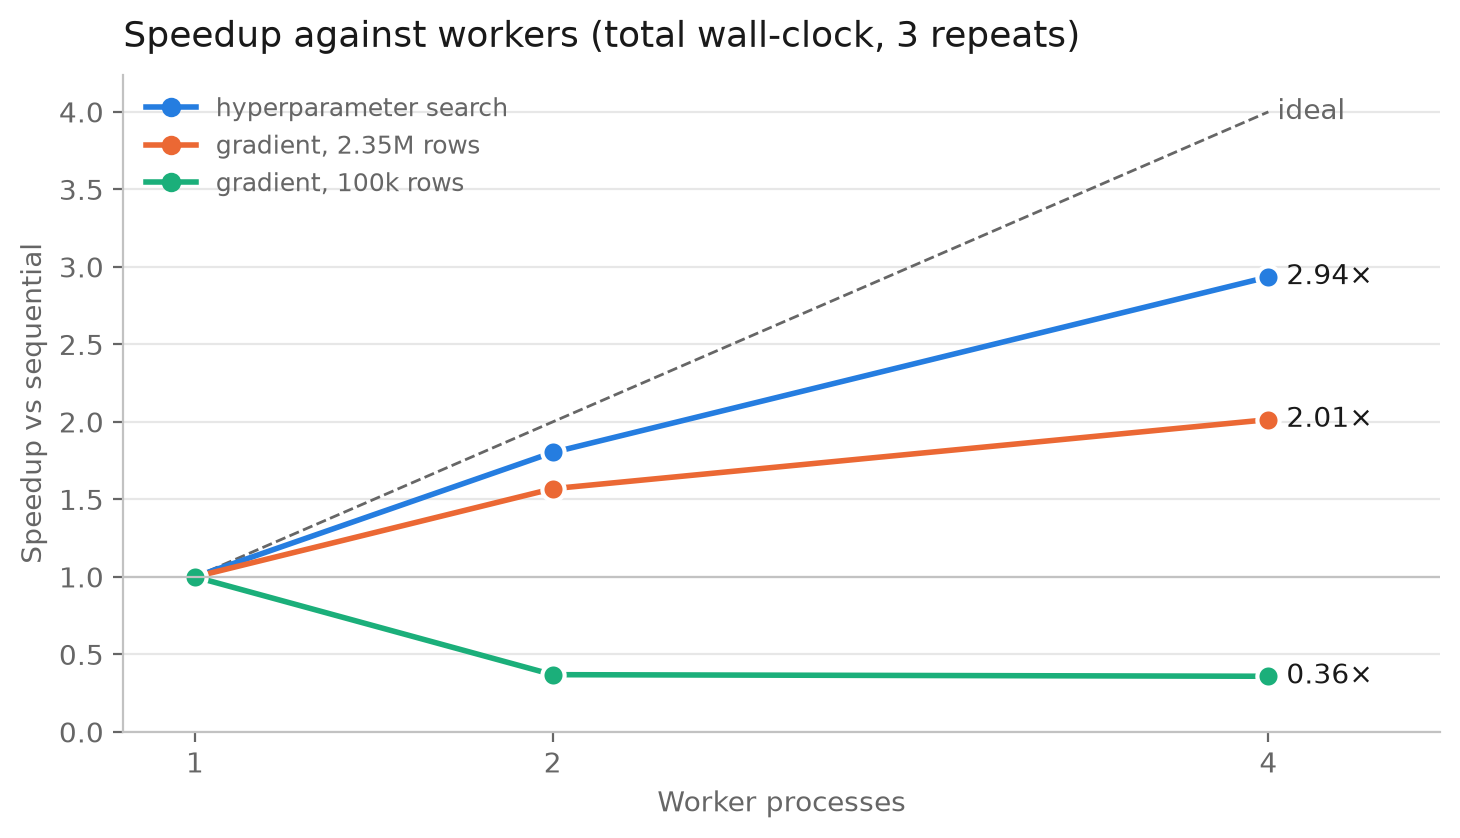

In [21]:
label = {'full': f'gradient, {c_sum["gd_benchmark"]["full"]["rows"] / 1e6:.2f}M rows' if len(Z) > 400_000 else f'gradient, {len(Z):,} rows',
         'small': 'gradient, 100k rows'}
series = {'hyperparameter search': search_time, **{label[k]: v for k, v in gd_time.items()}}
c_show(figs.speedup(series), 'C_parallel_speedup')

**Why the speedup is below ideal (Amdahl's law).** With parallel fraction $p$, $S(W) = 1/((1-p) + p/W)$. The table splits the gap to the ideal time into measured parts: starting the worker processes, sending weights and gradients back and forth in every iteration, and the rest – workers sharing one memory bus and waiting for the slowest shard. Shards are balanced (`slowest_over_mean` close to 1), so imbalance is *not* the cause here, unlike in the search. On a small dataset the fixed costs outweigh the work and the parallel version is slower.

**Memory.** The design matrix is stored once on disk and memory-mapped, so workers share one copy instead of receiving pickled pieces; inside a shard the gradient is accumulated in blocks of 4,096 rows.

## C8. Non-determinism: evidence and fixes
Each source is shown with repeated runs of the *same code on the same data* (before), then re-run after the fix. "Distinct" counts different output fingerprints; 1 means bit-identical.

In [22]:
nd = []
def record(source, fix, before, after, effect):
    nd.append({'source': source, 'runs_before': len(before), 'distinct_before': len(set(before)), 'fix': fix,
               'runs_after': len(after), 'distinct_after': len(set(after)), 'what changed': effect})
    assert len(set(after)) == 1, 'fix did not make the output identical'

# 1. floating-point sums combined in completion order
bad = [cp.train_gd(gd_paths['full'], iters=40, workers=PAR, reduce='completion', **gd_args)['w'] for _ in range(5)]
good = [cp.train_gd(gd_paths['full'], iters=40, workers=w, **gd_args)['w'] for w in (1, *[w for w in WORKERS if w > 1], PAR, PAR)]
spread = float(np.max([np.abs(b - bad[0]).max() for b in bad]))
record('Shard gradients added as workers finish', 'add in shard order 0..7', [cp.fingerprint(b) for b in bad], [cp.fingerprint(g) for g in good],
       f'weights differ by up to {spread:.1e} (addition is not associative)')
print('completion order :', [cp.fingerprint(b) for b in bad]); print('shard order      :', [cp.fingerprint(g) for g in good])
print('one weight, five runs:', [repr(float(b[0])) for b in bad])

completion order : ['edbcb610dc72', 'f9686f50d1e6', '8961e5f221e9', '43be0621a87f', '49275fe6a65a']
shard order      : ['95fb168d6b5c', '95fb168d6b5c', '95fb168d6b5c', '95fb168d6b5c', '95fb168d6b5c']
one weight, five runs: ['-0.018425788149991972', '-0.018425788149991976', '-0.018425788149992014', '-0.018425788149992014', '-0.01842578814999198']


In [23]:
# 2. unseeded random search
bad = [cp.random_search(gd_paths['full'], seed=None, workers=PAR) for _ in range(3)]
good = [cp.random_search(gd_paths['full'], seed=SEED, workers=w) for w in (1, PAR, PAR)]
record('Unseeded random search (ridge strength, row sample)', 'seed = [SEED, trial id], not per worker', [b['fingerprint'] for b in bad], [g['fingerprint'] for g in good],
       'best alpha ' + ' / '.join(f"{b['best_alpha']:.3g}" for b in bad))
pd.DataFrame([{'seed': s, 'run': i + 1, 'best_alpha': r['best_alpha'], 'best_MAE': r['best_MAE'], 'fingerprint': r['fingerprint']}
              for s, rs in (('none', bad), (SEED, good)) for i, r in enumerate(rs)])

,seed,run,best_alpha,best_MAE,fingerprint
0,none,1,37.961360,4.148237,88a86235c613
1,none,2,1.458486,4.151823,96d27f5b3d66
2,none,3,7.632159,4.149450,ae65e0e22866
3,420720,1,11.285192,4.154502,ae07af932cc2
4,420720,2,11.285192,4.154502,ae07af932cc2
5,420720,3,11.285192,4.154502,ae07af932cc2


In [24]:
# 3. results collected in completion order
bad = [cp.run_search(search_paths, tasks, PAR, collect='completion') for _ in range(5)]
good = [cp.run_search(search_paths, tasks, w) for w in (1, PAR, PAR)]
record('Search results collected with as_completed', 'sort by trial id; ties broken by trial id', [cp.rows_fingerprint(b['rows']) for b in bad], [cp.rows_fingerprint(g['rows']) for g in good],
       'row order of the results table')
for b in bad: print('completion order:', [r['trial'] for r in b['results']])
print('after the fix   :', [r['trial'] for r in good[-1]['results']])
assert good[0]['rows'] == search['rows']
c_sum['nondeterminism'] = nd
pd.DataFrame(nd)

completion order: [16, 13, 17, 14, 15, 12, 11, 8, 10, 7, 5, 2, 9, 6, 4, 1, 3, 0]
completion order: [16, 13, 17, 14, 15, 12, 8, 11, 10, 7, 2, 5, 9, 6, 1, 4, 3, 0]
completion order: [16, 13, 17, 14, 15, 12, 8, 11, 7, 10, 2, 5, 9, 6, 4, 1, 3, 0]
completion order: [13, 16, 17, 14, 15, 12, 8, 11, 10, 7, 2, 5, 9, 6, 4, 1, 3, 0]
completion order: [16, 13, 14, 17, 15, 12, 8, 11, 10, 7, 5, 2, 9, 6, 4, 1, 3, 0]
after the fix   : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]


,source,runs_before,distinct_before,fix,runs_after,distinct_after,what changed
0,Shard gradients added as workers finish,5,5,add in shard order 0..7,5,1,weights differ by up to 1.1e-15 (addition is n...
1,"Unseeded random search (ridge strength, row sa...",3,3,"seed = [SEED, trial id], not per worker",3,1,best alpha 38 / 1.46 / 7.63
2,Search results collected with as_completed,5,5,sort by trial id; ties broken by trial id,3,1,row order of the results table


### C8.1 Limits of the fixes
Fixing the order makes runs identical *for a given setup*. It does not make arithmetic exact. Changing the number of shards, the block size, the BLAS library or the machine can still move the last digits. That is why the shard count is a constant and why library versions are recorded above.

In [25]:
ref = cp.train_gd(gd_paths['full'], iters=40, workers=1, **gd_args)['w']
limits = []
for k in (4, 8, 16):
    w = cp.train_gd(gd_paths['full'], iters=40, workers=1, shards=k, **gd_args)['w']
    limits.append({'shards': k, 'fingerprint': cp.fingerprint(w), 'largest weight difference vs 8 shards': float(np.abs(w - ref).max()),
                   'largest prediction difference (min)': float(np.abs(minutes(w) - minutes(ref)).max())})
c_sum['limits'] = limits
pd.DataFrame(limits)

,shards,fingerprint,largest weight difference vs 8 shards,largest prediction difference (min)
0,4,9d89b81b0f6b,5.273559e-16,8.526513e-14
1,8,95fb168d6b5c,0.000000e+00,0.000000e+00
2,16,9bbdf24f1852,2.775558e-16,7.105427e-14


## C9. Where the error comes from: day by day

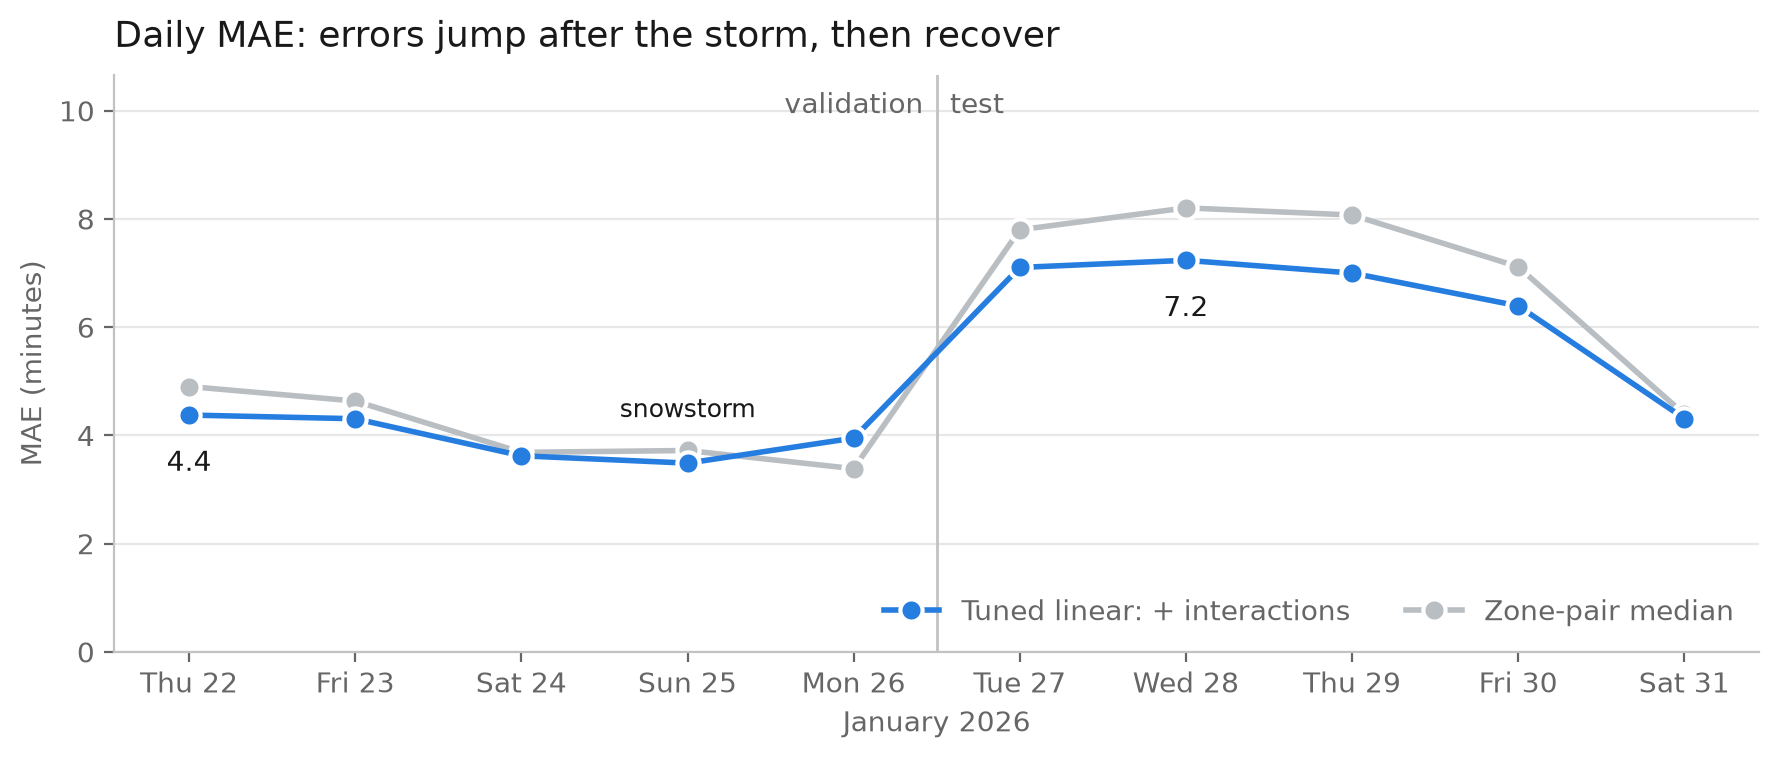

,Tuned linear: + interactions,Zone-pair median,split
2026-01-22,4.38,4.90,validation
2026-01-23,4.31,4.64,validation
2026-01-24,3.62,3.69,validation
2026-01-25,3.49,3.72,validation
2026-01-26,3.95,3.39,validation
2026-01-27,7.10,7.80,test
2026-01-28,7.24,8.21,test
2026-01-29,7.00,8.07,test
2026-01-30,6.39,7.12,test
2026-01-31,4.31,4.39,test


In [26]:
both = pd.concat([val, test])
day = both['pickup_datetime'].dt.normalize().to_numpy()
err = pd.DataFrame({best_name: np.abs(np.r_[lin_pred[best_name][0], lin_pred[best_name][1]] - both['duration_minutes'].to_numpy()),
                    'Zone-pair median': np.abs(np.r_[base_pred['Zone-pair median'][0], base_pred['Zone-pair median'][1]] - both['duration_minutes'].to_numpy())})
by_day = err.groupby(day).mean()
by_day['split'] = np.where(by_day.index < pd.Timestamp(TEST_START), 'validation', 'test')
c_show(figs.daily_error(by_day, STORM_DAY), 'C_daily_error')
c_sum['daily_mae'] = {f'{d:%Y-%m-%d}': round(float(v), 2) for d, v in by_day[best_name].items()}
by_day.round(2)

## C10. Pipeline and summary

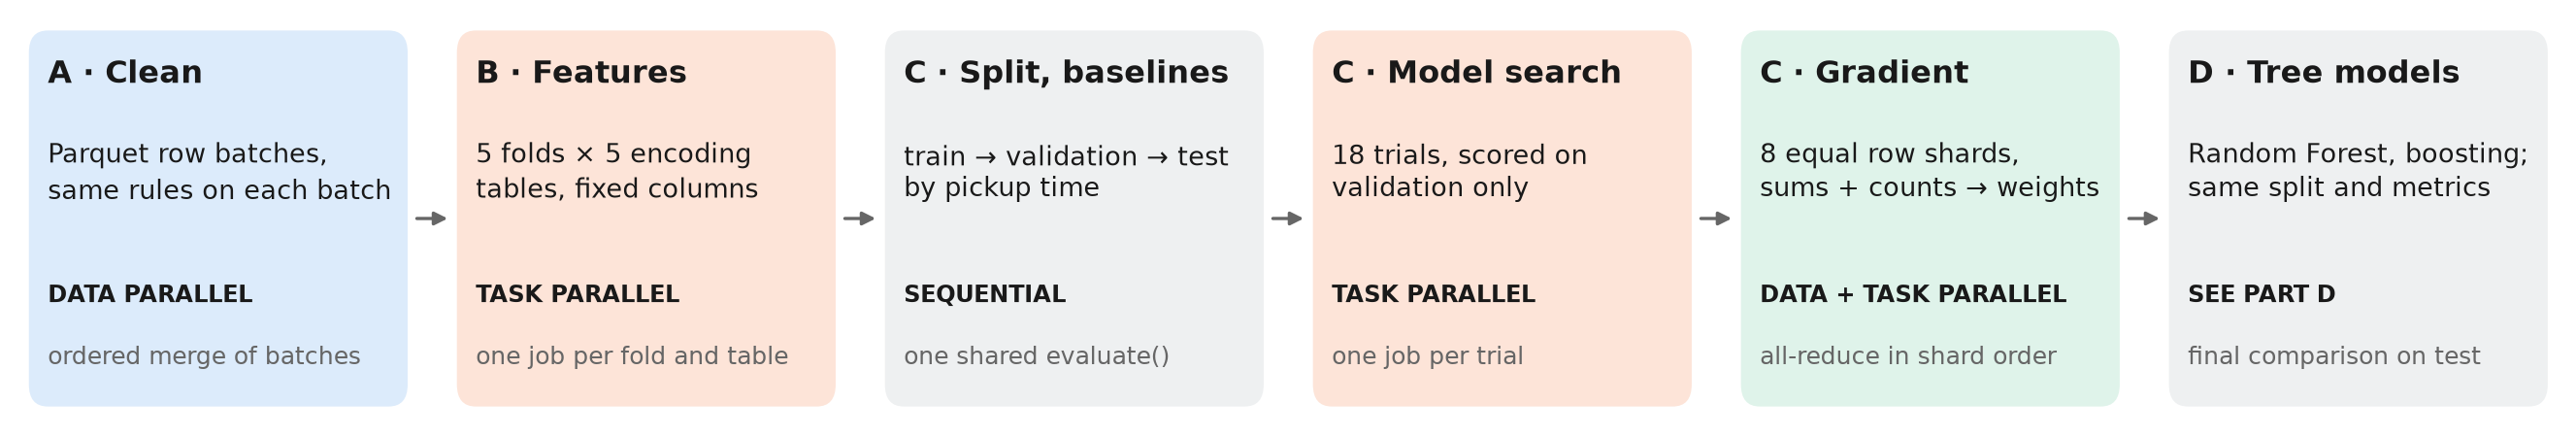

In [27]:
c_show(figs.pipeline(), 'C_pipeline')

In [28]:
t = board.table(); bl = 'Constant (train median)'; zp = 'Zone-pair median'
v = lambda n, c='validation_MAE': t.loc[n, c]
c_sum['scoreboard'] = t.round(4).reset_index().to_dict('records')
c_sum['headline'] = {'best_model': best_name, 'val_MAE': v(best_name), 'test_MAE': v(best_name, 'test_MAE'),
                     'val_vs_constant_pct': 100 * (1 - v(best_name) / v(bl)), 'val_vs_zone_pair_pct': 100 * (1 - v(best_name) / v(zp)),
                     'test_vs_constant_pct': 100 * (1 - v(best_name, 'test_MAE') / v(bl, 'test_MAE')),
                     'test_vs_zone_pair_pct': 100 * (1 - v(best_name, 'test_MAE') / v(zp, 'test_MAE')),
                     'test_bias': v(best_name, 'test_bias'), 'val_R2': v(best_name, 'validation_R2'), 'test_R2': v(best_name, 'test_R2')}
c_sum['headline'] = {k: (round(float(x), 3) if not isinstance(x, str) else x) for k, x in c_sum['headline'].items()}
c_sum['rows'] = {'all': len(df), 'train': len(train), 'validation': len(val), 'test': len(test)}

cp.close_store(); shutil.rmtree(CACHE, ignore_errors=True)
c_sum['runtime_s'] = round(time.perf_counter() - C_START, 1)
(C_OUT / 'c_summary.json').write_text(json.dumps(c_sum, indent=2, default=lambda o: o.item() if hasattr(o, 'item') else str(o)), encoding='utf-8')

h, s4, g4 = c_sum['headline'], search_time.iloc[-1], gd_time['full'].iloc[-1]
display(Markdown(f'''
- **Split:** {len(train):,} train / {len(val):,} validation / {len(test):,} test trips, strictly by pickup time.
- **Baseline to beat:** zone-pair median, validation MAE {v(zp):.2f} min (constant: {v(bl):.2f}).
- **Best Part C model:** {best_name}, validation MAE **{h["val_MAE"]:.2f}** min ({h["val_vs_constant_pct"]:.0f}% below the constant, {h["val_vs_zone_pair_pct"]:.1f}% below the zone-pair median), test MAE **{h["test_MAE"]:.2f}** min, test bias {h["test_bias"]:.1f} min.
- **Hyperparameter search:** {s4["speedup"]:.2f}× with {int(s4["workers"])} workers, identical output (Amdahl p = {c_sum["amdahl"]["p_search"]}).
- **Parallel gradient:** {g4["speedup"]:.2f}× with {int(g4["workers"])} workers on {len(Z):,} rows, identical output (p = {c_sum["amdahl"]["p_gradient"]}).
- **Non-determinism:** {sum(x["distinct_before"] > 1 for x in nd)} of {len(nd)} sources gave differing output before the fix; every run after the fix is bit-identical.
- **Run time of Part C:** {c_sum["runtime_s"]:.0f} s on {c_sum["environment"]["cores_usable"]} usable cores.
'''))


- **Split:** 2,348,057 train / 507,763 validation / 648,552 test trips, strictly by pickup time.
- **Baseline to beat:** zone-pair median, validation MAE 4.21 min (constant: 8.19).
- **Best Part C model:** Tuned linear: + interactions, validation MAE **4.02** min (51% below the constant, 4.4% below the zone-pair median), test MAE **6.35** min, test bias -4.6 min.
- **Hyperparameter search:** 2.94× with 4 workers, identical output (Amdahl p = 0.883).
- **Parallel gradient:** 2.01× with 4 workers on 2,348,057 rows, identical output (p = 0.688).
- **Non-determinism:** 3 of 3 sources gave differing output before the fix; every run after the fix is bit-identical.
- **Run time of Part C:** 240 s on 8 usable cores.
